# Iranian License Plate Character Recognition Using KNN

## Project Overview

This project is the first stage of an Iranian license plate recognition system.

The goal of this stage is to recognize individual characters that may appear on Iranian license plates using the K-Nearest Neighbors (KNN) algorithm.

The system performs image preprocessing and converts each character image into numerical features before classification.

### Pipeline

Character Image  
↓  
Grayscale  
↓  
Resize (20×30)  
↓  
Flatten (600 Features)  
↓  
Train/Test Split  
↓  
Normalization  
↓  
KNN Classification  
↓  
Character Prediction

## 1. Import Libraries

In [9]:
import os
import json
import random
import joblib
import numpy as np
import matplotlib.pyplot as plt

from collections import Counter
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

## 2. Project Configuration

In [10]:
dataset_path = r"E:\Iranian-License-Plate-Character-Recognition\Iranis_Dataset"

target_size = (20, 30)

model_dir = "models"
assets_dir = "assets"

os.makedirs(model_dir, exist_ok=True)
os.makedirs(assets_dir, exist_ok=True)

## 3. Dataset Exploration

In this section, we examine the available classes and the number of images in each class.

In [11]:
classes = sorted(os.listdir(dataset_path))

print("Classes:")
print(classes)

print("\nNumber of classes:", len(classes))

Classes:
['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'A', 'B', 'D', 'Gh', 'H', 'J', 'L', 'M', 'N', 'P', 'PuV', 'PwD', 'Sad', 'Sin', 'T', 'Taxi', 'V', 'Y']

Number of classes: 28


In [12]:
class_counts = {}

for cls in classes:
    class_path = os.path.join(dataset_path, cls)
    
    if os.path.isdir(class_path):
        class_counts[cls] = len(os.listdir(class_path))

total_images = sum(class_counts.values())

print(f"Total number of images: {total_images}")
print(f"Number of classes: {len(classes)}")

print("\nImages per class:")

for cls, count in class_counts.items():
    print(f"{cls}: {count}")

Total number of images: 83844
Number of classes: 28

Images per class:
0: 2501
1: 3495
2: 3930
3: 2745
4: 5774
5: 3610
6: 5753
7: 3736
8: 3583
9: 3528
A: 2517
B: 2511
D: 2504
Gh: 2482
H: 2558
J: 2505
L: 2502
M: 2500
N: 2558
P: 2519
PuV: 2508
PwD: 2502
Sad: 2515
Sin: 2445
T: 2512
Taxi: 2551
V: 2509
Y: 2491


### Class Distribution

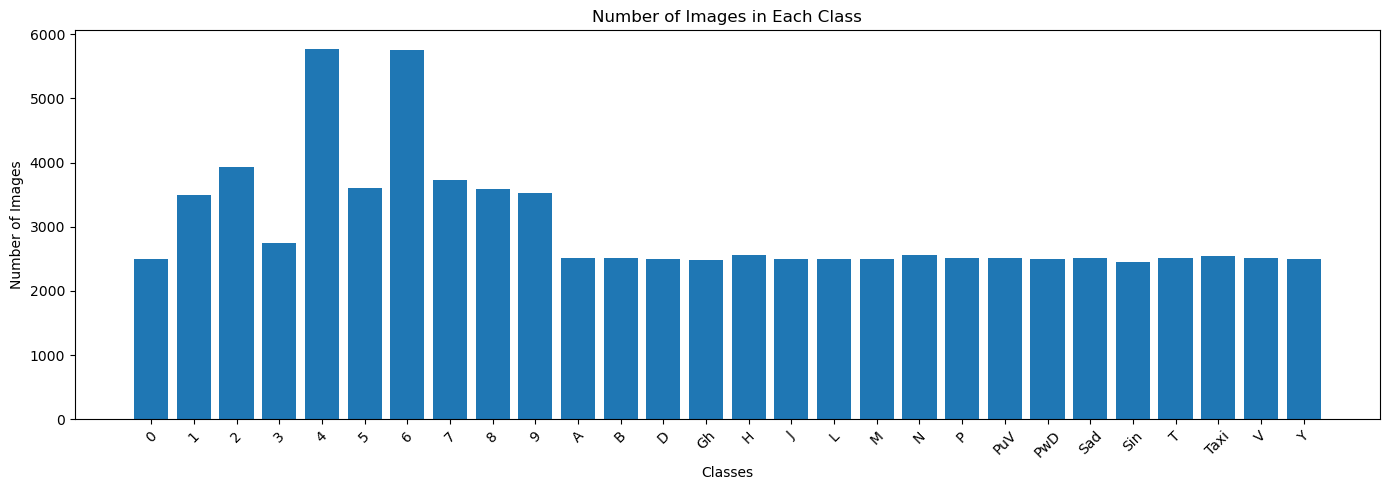

In [13]:
plt.figure(figsize=(14, 5))

plt.bar(
    class_counts.keys(),
    class_counts.values()
)

plt.xlabel("Classes")
plt.ylabel("Number of Images")
plt.title("Number of Images in Each Class")

plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    os.path.join(assets_dir, "class_distribution.png"),
    dpi=300
)

plt.show()

## 4. Sample Images

Displaying random samples from different classes.

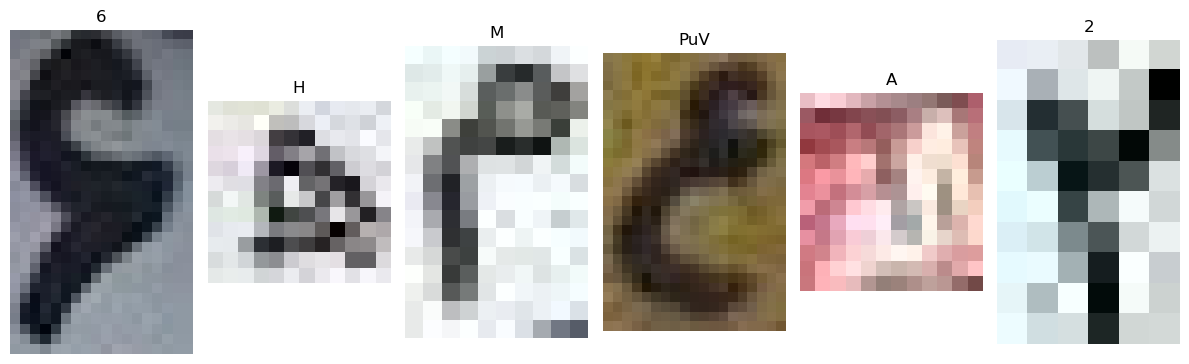

In [14]:
sample_classes = random.sample(classes, min(6, len(classes)))

plt.figure(figsize=(12, 4))

for i, cls in enumerate(sample_classes):
    
    class_path = os.path.join(dataset_path, cls)
    files = os.listdir(class_path)

    random_file = random.choice(files)
    image_path = os.path.join(class_path, random_file)

    with Image.open(image_path) as image:
        
        plt.subplot(1, len(sample_classes), i + 1)
        plt.imshow(image)
        plt.title(cls)
        plt.axis("off")

plt.tight_layout()
plt.show()

## 5. Image Size Analysis

Images in the dataset may have different dimensions.  
We examine their sizes before applying preprocessing.

In [15]:
image_sizes = []

for cls in classes:
    
    class_path = os.path.join(dataset_path, cls)
    
    for file_name in os.listdir(class_path):
        
        image_path = os.path.join(class_path, file_name)

        try:
            with Image.open(image_path) as image:
                image_sizes.append(image.size)

        except Exception as e:
            print(f"Error reading {image_path}: {e}")

print("Total images analyzed:", len(image_sizes))

print("\nMinimum width:",
      min(size[0] for size in image_sizes))

print("Maximum width:",
      max(size[0] for size in image_sizes))

print("Minimum height:",
      min(size[1] for size in image_sizes))

print("Maximum height:",
      max(size[1] for size in image_sizes))

Total images analyzed: 83844

Minimum width: 2
Maximum width: 96
Minimum height: 6
Maximum height: 112


In [16]:
size_counts = Counter(image_sizes)

print("10 most common image sizes:\n")

for size, count in size_counts.most_common(10):
    print(f"{size}: {count}")

10 most common image sizes:

(6, 11): 1149
(6, 10): 1143
(7, 11): 1010
(7, 12): 962
(6, 9): 675
(7, 10): 643
(8, 12): 628
(5, 10): 621
(9, 12): 593
(6, 12): 579


## 6. Image Preprocessing

Each image goes through the following preprocessing steps:

1. Convert to Grayscale
2. Resize to 20×30 pixels
3. Convert to NumPy Array
4. Flatten into a one-dimensional vector

Each processed image will contain:

20 × 30 = 600 features

Original image size: (9, 14)
Processed image size: (20, 30)
Array shape: (30, 20)
Number of features: 600


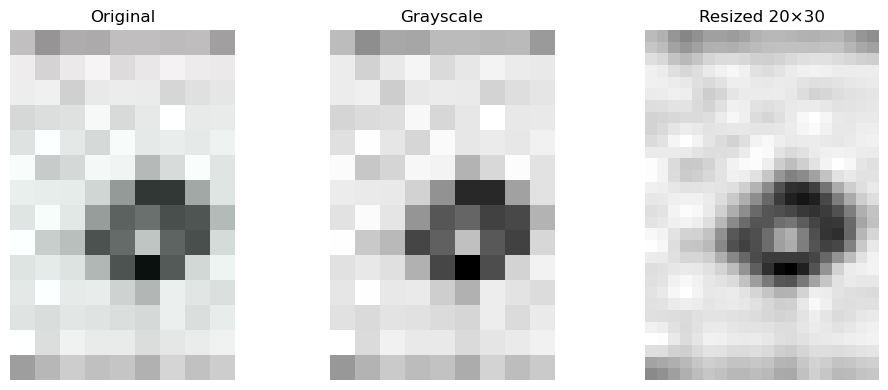

In [17]:
sample_class = classes[0]

sample_class_path = os.path.join(
    dataset_path,
    sample_class
)

sample_file = os.listdir(sample_class_path)[0]

sample_path = os.path.join(
    sample_class_path,
    sample_file
)

with Image.open(sample_path) as image:

    original_image = image.copy()

gray_image = original_image.convert("L")

resized_image = gray_image.resize(target_size)

image_array = np.array(resized_image)

flattened_image = image_array.flatten()

print("Original image size:", original_image.size)
print("Processed image size:", resized_image.size)

print("Array shape:", image_array.shape)
print("Number of features:", len(flattened_image))

plt.figure(figsize=(10, 4))

plt.subplot(1, 3, 1)
plt.imshow(original_image)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(gray_image, cmap="gray")
plt.title("Grayscale")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(resized_image, cmap="gray")
plt.title("Resized 20×30")
plt.axis("off")

plt.tight_layout()
plt.show()

## 7. Dataset Preparation

All images are preprocessed and converted into feature vectors.

- X contains image features
- y contains class labels

In [18]:
X = []
y = []

for cls in classes:
    
    class_path = os.path.join(dataset_path, cls)
    files = os.listdir(class_path)

    for file_name in files:

        image_path = os.path.join(
            class_path,
            file_name
        )

        try:
            with Image.open(image_path) as image:

                image = image.convert("L")
                image = image.resize(target_size)

                image_array = np.array(image)

                flattened_image = image_array.flatten()

                X.append(flattened_image)
                y.append(cls)

        except Exception as e:
            print(
                f"Error processing {image_path}: {e}"
            )

### Dataset Structure

In [19]:
X = np.array(X)
y = np.array(y)

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nX data type:", X.dtype)
print("y data type:", y.dtype)

print("\nNumber of samples:", len(X))
print("Number of features per image:", X.shape[1])

X shape: (83844, 600)
y shape: (83844,)

X data type: uint8
y data type: <U4

Number of samples: 83844
Number of features per image: 600


## 8. Train/Test Split

The dataset is divided into:

- 80% Training Data
- 20% Testing Data

Stratified splitting is used to preserve the class distribution.

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("\ny_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (67075, 600)
X_test shape: (16769, 600)

y_train shape: (67075,)
y_test shape: (16769,)


## 9. Feature Normalization

Pixel values are converted from:

0–255

to:

0–1

In [21]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("X_train minimum:", X_train.min())
print("X_train maximum:", X_train.max())

print("\nX_test minimum:", X_test.min())
print("X_test maximum:", X_test.max())

X_train minimum: 0.0
X_train maximum: 1.0

X_test minimum: 0.0
X_test maximum: 1.0


## 10. KNN Model Training

The final model uses:

K = 3

In [22]:
knn = KNeighborsClassifier(
    n_neighbors=3,
    n_jobs=-1
)

knn.fit(X_train, y_train)

print("KNN model is ready!")

KNN model is ready!


## 11. Model Evaluation

In [23]:
y_pred = knn.predict(X_test)

print("Number of predictions:", len(y_pred))

C:\Users\bc\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\bc\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\bc\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\bc\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\bc\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable

Number of predictions: 16769


### Accuracy

In [24]:
test_accuracy = accuracy_score(
    y_test,
    y_pred
)

print(f"Test Accuracy: {test_accuracy:.4f}")
print(
    f"Test Accuracy Percentage: "
    f"{test_accuracy * 100:.2f}%"
)

Test Accuracy: 0.9893
Test Accuracy Percentage: 98.93%


### Classification Report

In [25]:
report = classification_report(
    y_test,
    y_pred,
    labels=classes
)

print(report)

              precision    recall  f1-score   support

           0       0.99      1.00      1.00       500
           1       0.99      1.00      0.99       699
           2       0.94      0.96      0.95       786
           3       0.95      0.92      0.93       549
           4       0.99      0.99      0.99      1155
           5       1.00      0.98      0.99       722
           6       1.00      0.99      0.99      1151
           7       1.00      0.99      0.99       747
           8       1.00      0.99      0.99       717
           9       1.00      0.99      1.00       706
           A       1.00      1.00      1.00       503
           B       1.00      1.00      1.00       502
           D       0.99      1.00      0.99       501
          Gh       1.00      1.00      1.00       496
           H       1.00      1.00      1.00       512
           J       1.00      0.99      1.00       501
           L       1.00      1.00      1.00       500
           M       1.00    

## 12. Confusion Matrix

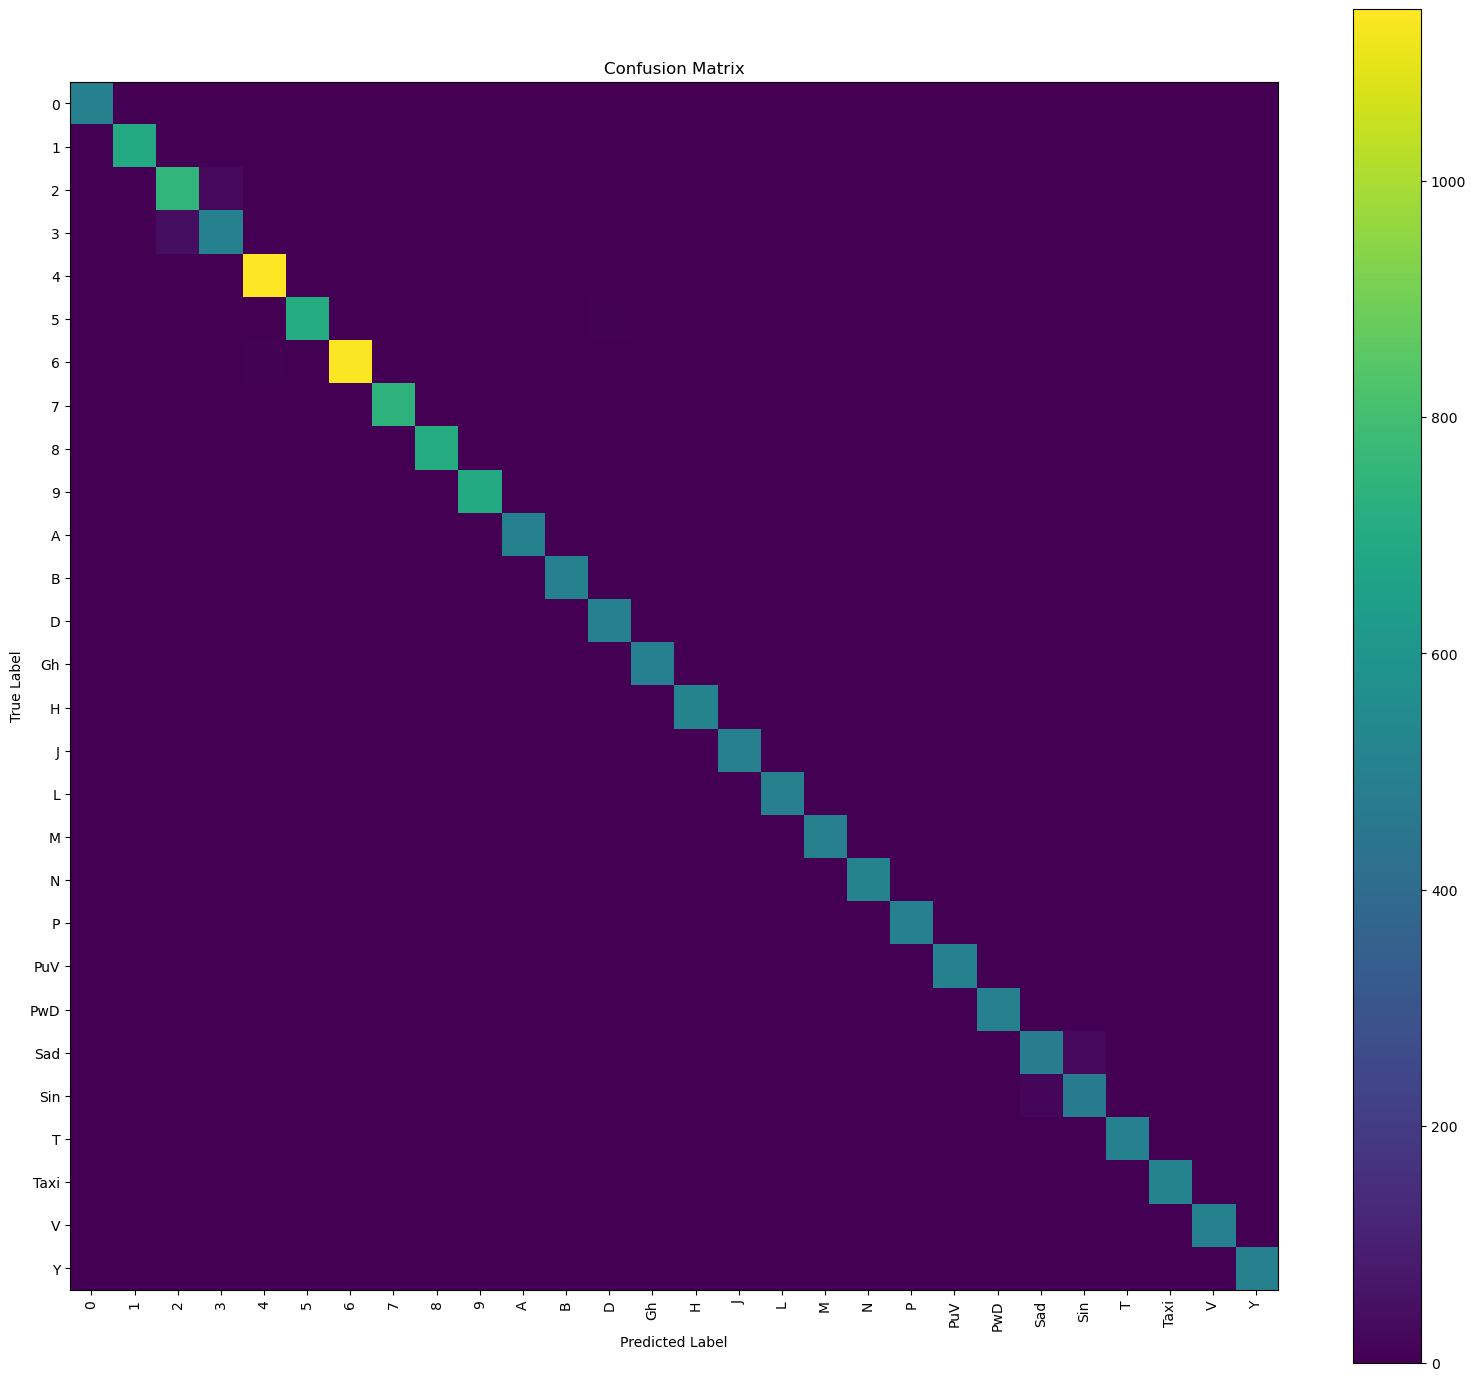

In [26]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=classes
)

plt.figure(figsize=(16, 14))

plt.imshow(cm)

plt.colorbar()

plt.xticks(
    range(len(classes)),
    classes,
    rotation=90
)

plt.yticks(
    range(len(classes)),
    classes
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.title("Confusion Matrix")

plt.tight_layout()

plt.savefig(
    os.path.join(
        assets_dir,
        "confusion_matrix.png"
    ),
    dpi=300
)

plt.show()

## 13. Misclassification Analysis

We analyze the most common classification errors.

In [27]:
cm_copy = cm.copy()

np.fill_diagonal(
    cm_copy,
    0
)

top_errors = []

for _ in range(10):

    i, j = np.unravel_index(
        np.argmax(cm_copy),
        cm_copy.shape
    )

    count = cm_copy[i, j]

    if count == 0:
        break

    top_errors.append(
        (
            classes[i],
            classes[j],
            int(count)
        )
    )

    cm_copy[i, j] = 0

print("Top misclassifications:\n")

for true_label, predicted_label, count in top_errors:

    print(
        f"True: {true_label} → "
        f"Predicted: {predicted_label} "
        f"({count} images)"
    )

Top misclassifications:

True: 3 → Predicted: 2 (43 images)
True: 2 → Predicted: 3 (26 images)
True: Sad → Predicted: Sin (24 images)
True: Sin → Predicted: Sad (14 images)
True: 5 → Predicted: D (7 images)
True: 6 → Predicted: 4 (6 images)
True: 7 → Predicted: 2 (4 images)
True: 2 → Predicted: 7 (3 images)
True: 9 → Predicted: 1 (3 images)
True: 2 → Predicted: 1 (2 images)


### Examples of Misclassified Images

Number of 3 → 2 errors: 43


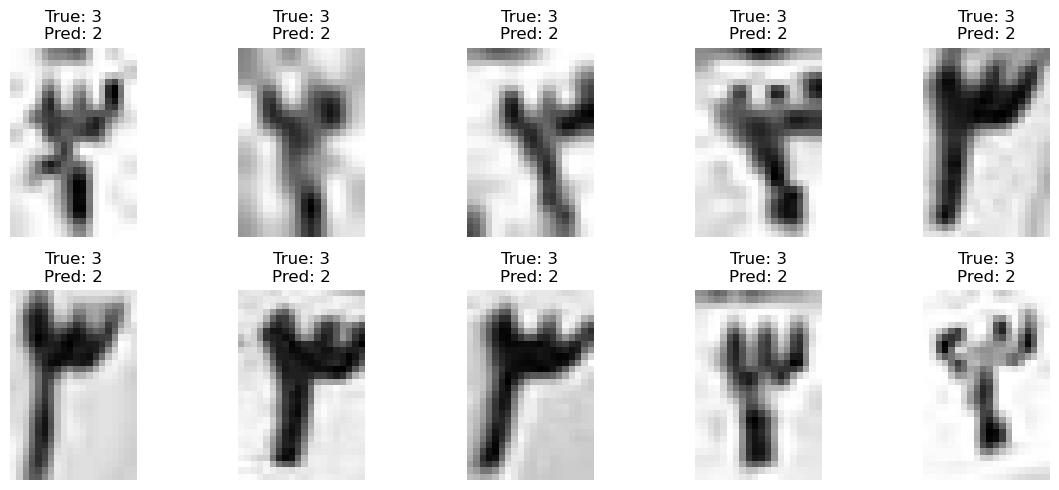

In [28]:
true_class = "3"
predicted_class = "2"

wrong_indices = np.where(
    (y_test == true_class) &
    (y_pred == predicted_class)
)[0]

print(
    f"Number of "
    f"{true_class} → {predicted_class} errors:",
    len(wrong_indices)
)

plt.figure(figsize=(12, 5))

for i, index in enumerate(wrong_indices[:10]):

    image = X_test[index].reshape(30, 20)

    plt.subplot(2, 5, i + 1)

    plt.imshow(
        image,
        cmap="gray"
    )

    plt.title(
        f"True: {true_class}\n"
        f"Pred: {predicted_class}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

## 14. K Value Comparison

Different values of K are tested to compare their performance.

In [29]:
k_values = [1, 3, 5, 7]

results = {}

for k in k_values:

    print(f"Testing K = {k}...")

    model = KNeighborsClassifier(
        n_neighbors=k,
        n_jobs=-1
    )

    model.fit(
        X_train,
        y_train
    )

    k_predictions = model.predict(
        X_test
    )

    k_accuracy = accuracy_score(
        y_test,
        k_predictions
    )

    results[k] = k_accuracy

    print(
        f"Accuracy: "
        f"{k_accuracy * 100:.2f}%\n"
    )

Testing K = 1...
Accuracy: 98.97%

Testing K = 3...
Accuracy: 98.93%

Testing K = 5...
Accuracy: 98.81%

Testing K = 7...
Accuracy: 98.74%



### KNN Accuracy Comparison

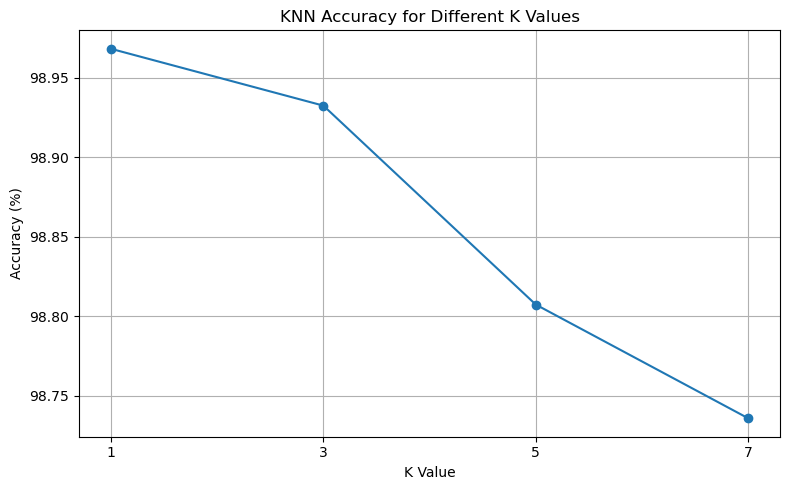

In [30]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(results.keys()),
    [
        accuracy * 100
        for accuracy in results.values()
    ],
    marker="o"
)

plt.xlabel("K Value")
plt.ylabel("Accuracy (%)")

plt.title(
    "KNN Accuracy for Different K Values"
)

plt.xticks(k_values)

plt.grid(True)

plt.tight_layout()

plt.savefig(
    os.path.join(
        assets_dir,
        "k_comparison.png"
    ),
    dpi=300
)

plt.show()

## 15. Final Model Summary

In [31]:
print("=" * 50)

print("FINAL MODEL SUMMARY")

print("=" * 50)

print(f"Dataset: Iranis Dataset")
print(f"Total Samples: {len(X)}")
print(f"Number of Classes: {len(classes)}")

print(f"\nTraining Samples: {len(X_train)}")
print(f"Testing Samples: {len(X_test)}")

print(f"\nAlgorithm: K-Nearest Neighbors")
print(f"Final K Value: 3")

print(f"\nImage Size: {target_size[0]} × {target_size[1]}")
print(f"Features per Image: {X.shape[1]}")

print(
    f"\nTest Accuracy: "
    f"{test_accuracy * 100:.2f}%"
)

print("=" * 50)

FINAL MODEL SUMMARY
Dataset: Iranis Dataset
Total Samples: 83844
Number of Classes: 28

Training Samples: 67075
Testing Samples: 16769

Algorithm: K-Nearest Neighbors
Final K Value: 3

Image Size: 20 × 30
Features per Image: 600

Test Accuracy: 98.93%


## 16. Save Final Model and Project Metadata

The trained model and project information are saved for use in the application.

In [32]:
model_path = os.path.join(
    model_dir,
    "knn_model.pkl"
)

joblib.dump(
    knn,
    model_path
)

print(f"Model saved successfully to:\n{model_path}")

Model saved successfully to:
models\knn_model.pkl


In [33]:
model_info = {
    "project_name": "Iranian Character Image Classification",
    "dataset_name": "Iranis Dataset",
    
    "algorithm": "K-Nearest Neighbors",
    "k_value": 3,
    
    "test_accuracy": round(
        float(test_accuracy * 100),
        2
    ),
    
    "total_samples": int(len(X)),
    "training_samples": int(len(X_train)),
    "testing_samples": int(len(X_test)),
    
    "number_of_classes": int(len(classes)),
    "classes": classes,
    
    "image_width": target_size[0],
    "image_height": target_size[1],
    
    "features_per_image": int(X.shape[1]),
    
    "preprocessing": [
        "Grayscale",
        "Resize to 20x30",
        "Flatten",
        "Normalization (0-1)"
    ],
    
    "k_comparison": {
        str(k): round(
            float(accuracy * 100),
            2
        )
        for k, accuracy in results.items()
    }
}

In [34]:
metadata_path = os.path.join(
    model_dir,
    "model_info.json"
)

with open(
    metadata_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        model_info,
        file,
        indent=4,
        ensure_ascii=False
    )

print(
    f"Model metadata saved successfully to:\n"
    f"{metadata_path}"
)

Model metadata saved successfully to:
models\model_info.json
